   Mean Radius  Mean Texture  Mean Perimeter  Mean Area  Mean Smoothness  \
0        17.99         10.38          122.80     1001.0           0.1184   
1        20.57         17.77          132.90     1326.0           0.0847   
2        13.54         14.36           87.46      566.3           0.0978   
3        11.42         20.38           77.58      386.1           0.1425   
4        19.69         21.25          130.00     1203.0           0.1096   
5        12.45         15.70           82.57      477.1           0.1278   

   Diagnosis  
0  Malignant  
1  Malignant  
2     Benign  
3     Benign  
4  Malignant  
5     Benign  
Accuracy Score: 0.6666666666666666
Confusion Matrix:
 [[1 1]
 [0 1]]
Classification Report:
               precision    recall  f1-score   support

      Benign       1.00      0.50      0.67         2
   Malignant       0.50      1.00      0.67         1

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67        

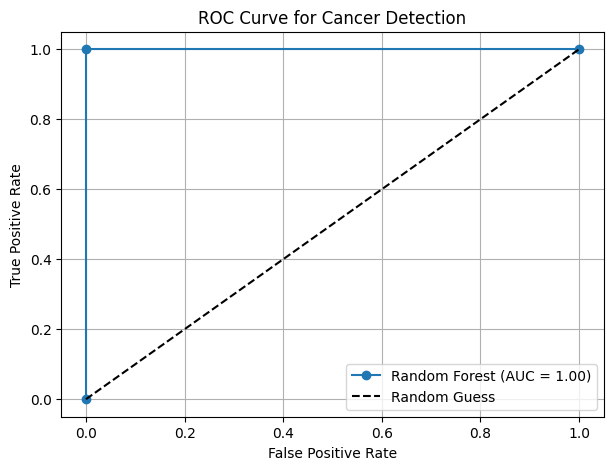

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score

data = {
    'Mean Radius': [17.99, 20.57, 13.54, 11.42, 19.69, 12.45],
    'Mean Texture': [10.38, 17.77, 14.36, 20.38, 21.25, 15.70],
    'Mean Perimeter': [122.80, 132.90, 87.46, 77.58, 130.00, 82.57],
    'Mean Area': [1001.0, 1326.0, 566.3, 386.1, 1203.0, 477.1],
    'Mean Smoothness': [0.1184, 0.0847, 0.0978, 0.1425, 0.1096, 0.1278],
    'Diagnosis': ['Malignant', 'Malignant', 'Benign', 'Benign', 'Malignant', 'Benign']
}

df = pd.DataFrame(data)
print(df)

df['Diagnosis'] = df['Diagnosis'].map({'Malignant': 1, 'Benign': 0})

X = df.drop('Diagnosis', axis=1)
y = df['Diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("Classification Report:\n", classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=['Benign', 'Malignant'],
    zero_division=0
))

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

print("AUC Score:", auc_score)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, marker='o', label=f'Random Forest (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Cancer Detection')
plt.legend()
plt.grid(True)
plt.show()